# Furnace_analysis.csv 튜브 Furnace 이상 탐지 데이터 분석

`Furnace_Tube_Data.csv` 에 전처리와 파생 컬럼(`이상치개수`, `정상여부`, `요일`)을 더한 분석용 데이터입니다.

1. 데이터 로드 및 기본 점검
2. 원본(Furnace_Tube_Data)과의 관계 검증
3. `이상치개수` 생성 규칙 재현 (IQR)
4. `정상여부` 생성 규칙 재현
5. 이상(정상여부=1) 분포 — Run / Code / Process / 시간
6. 이상을 만드는 센서
7. 전역 IQR vs Run별 IQR — 라벨의 한계
8. 분류 모델 (Run 단위 GroupKFold)
9. 시각화 & 결론

## 1. 데이터 로드 및 기본 점검

In [1]:
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', '{:,.4f}'.format)   # 지수 표기 대신 천 단위 콤마 + 소수점 4자리 (표시만, 데이터는 원본 유지)

df = pd.read_csv('../data/Furnace_analysis.csv')
df['dt'] = pd.to_datetime(df['Datetime'])
df['run'] = (df['Code_Num'] != df['Code_Num'].shift()).cumsum()   # Code_Num 전환 = 가동 구간(Run) 경계

NUM = ['Z1_Temp', 'Z1_OP1', 'ST',
       'Tube_Furnace1_OP', 'Tube_Furnace2_OP', 'Tube_Furnace3_OP', 'Tube_Furnace4_OP', 'Tube_Furnace_CP',
       'Tube_Furnace1_Temp', 'Tube_Furnace2_Temp', 'Tube_Furnace3_Temp', 'Tube_Furnace4_Temp']

print(f'데이터 크기: {df.shape[0]:,}행 × {df.shape[1] - 2}열 (dt, run 보조 컬럼 제외)')
print(f'결측치 합계: {df[NUM].isna().sum().sum():,}')
print(f'기간: {df["dt"].min()} ~ {df["dt"].max()} / Run {df["run"].nunique()}개')
df.head()

데이터 크기: 231,123행 × 18열 (dt, run 보조 컬럼 제외)
결측치 합계: 0
기간: 2022-01-03 11:22:00 ~ 2022-01-15 19:49:00 / Run 11개


,Process_Type,Datetime,Code_Num,Z1_Temp,Z1_OP1,ST,Tube_Furnace1_OP,Tube_Furnace2_OP,Tube_Furnace3_OP,Tube_Furnace4_OP,Tube_Furnace_CP,Tube_Furnace1_Temp,Tube_Furnace2_Temp,Tube_Furnace3_Temp,Tube_Furnace4_Temp,이상치개수,정상여부,요일,dt,run
0,OP-A,2022-01-03 11:22:00,GroupA,100.5097,75.6648,69.0930,73.5274,59.9894,52.2495,72.1349,0.4505,884.5382,868.7595,885.0257,884.9877,1,0,Monday,2022-01-03 11:22:00,1
1,OP-A,2022-01-03 11:22:00,GroupA,100.5097,75.6706,69.0930,79.1492,62.0272,50.6171,71.2452,0.4574,878.1169,883.8213,890.7408,894.4306,1,0,Monday,2022-01-03 11:22:00,1
2,OP-A,2022-01-03 11:22:00,GroupA,99.6142,75.6776,68.7246,78.9463,62.2355,52.2183,72.7056,0.4549,866.4420,882.8500,864.3731,893.5305,1,0,Monday,2022-01-03 11:22:00,1
3,OP-A,2022-01-03 11:22:00,GroupA,99.3762,75.8656,69.1611,78.4457,61.6083,52.8636,73.9756,0.4565,876.3505,906.2085,891.1079,896.3476,2,0,Monday,2022-01-03 11:22:00,1
4,OP-C,2022-01-03 11:22:00,GroupA,99.8091,73.6468,69.1811,76.6738,61.5893,52.2972,71.8879,0.4601,903.5877,867.2151,893.2069,871.5943,1,0,Monday,2022-01-03 11:22:00,1


In [2]:
desc = df[NUM + ['이상치개수', '정상여부']].describe().T
desc['count'] = desc['count'].astype(int)
desc['nunique'] = df[NUM + ['이상치개수', '정상여부']].nunique()

display(desc)

,count,mean,std,min,25%,50%,75%,max,nunique
Z1_Temp,231123,100.5097,0.4272,98.3709,100.2340,100.5066,100.7794,102.6640,229234
Z1_OP1,231123,72.6226,3.0091,52.9816,71.3191,72.9036,74.4050,84.5911,93274
ST,231123,69.0930,1.0782,64.9914,68.2533,69.0850,69.9961,71.5270,231024
Tube_Furnace1_OP,231123,75.3096,20.6517,0.0054,68.8980,78.6921,87.6814,101.0000,230835
Tube_Furnace2_OP,231123,47.5720,4.4135,35.2017,45.2192,46.7344,48.4129,66.8253,231090
Tube_Furnace3_OP,231123,50.5330,1.9651,37.5194,49.4197,50.6469,51.7991,59.4909,231098
Tube_Furnace4_OP,231123,70.2475,2.2818,56.7485,68.8756,70.2691,71.5544,83.4108,231071
Tube_Furnace_CP,231123,0.4497,0.0442,0.0980,0.4520,0.4549,0.4578,0.9163,229402
Tube_Furnace1_Temp,231123,884.5382,14.6055,848.2845,872.0577,884.5277,896.9606,920.8327,231056
Tube_Furnace2_Temp,231123,885.0415,14.4181,858.6697,872.5620,885.0464,897.5374,911.3588,231064


## 2. 원본(Furnace_Tube_Data)과의 관계 검증

In [3]:
raw = pd.read_csv('../data/Furnace_Tube_Data.csv')
same_cols = [c for c in raw.columns if c in df.columns]
extra = [c for c in df.columns if c not in raw.columns and c not in ('dt', 'run')]

print(f'행 수 동일: {len(raw) == len(df)} ({len(df):,}행)')
print(f'추가 컬럼: {extra}')
print(f'Datetime: 원본 "{raw["Datetime"].iloc[0]}" → "{df["Datetime"].iloc[0]}" (초 :00 추가), 파싱 후 동일 = {(pd.to_datetime(raw["Datetime"]) == df["dt"]).all()}')
print()
print(f'[결측치 대체 방식 확인]')
for c in NUM:
    m = raw[c].isna()
    if m.sum() == 0:
        continue
    kept = np.allclose(raw.loc[~m, c], df.loc[~m, c])
    filled = df.loc[m, c].unique()
    is_mean = len(filled) == 1 and np.isclose(filled[0], raw[c].mean())
    print(f'  {c:<20s}: 결측 {m.sum():>3}개 → {filled[0]:,.4f} 로 대체 | 전체 평균과 일치 {is_mean} | 나머지 값 보존 {kept}')

행 수 동일: True (231,123행)
추가 컬럼: ['이상치개수', '정상여부', '요일']
Datetime: 원본 "2022-01-03 11:22" → "2022-01-03 11:22:00" (초 :00 추가), 파싱 후 동일 = True

[결측치 대체 방식 확인]
  Z1_Temp             : 결측  25개 → 100.5097 로 대체 | 전체 평균과 일치 True | 나머지 값 보존 True
  ST                  : 결측  25개 → 69.0930 로 대체 | 전체 평균과 일치 True | 나머지 값 보존 True
  Tube_Furnace1_OP    : 결측 254개 → 75.3096 로 대체 | 전체 평균과 일치 True | 나머지 값 보존 True
  Tube_Furnace1_Temp  : 결측   5개 → 884.5382 로 대체 | 전체 평균과 일치 True | 나머지 값 보존 True
  Tube_Furnace2_Temp  : 결측  10개 → 885.0415 로 대체 | 전체 평균과 일치 True | 나머지 값 보존 True
  Tube_Furnace3_Temp  : 결측   9개 → 885.0257 로 대체 | 전체 평균과 일치 True | 나머지 값 보존 True
  Tube_Furnace4_Temp  : 결측  15개 → 884.9877 로 대체 | 전체 평균과 일치 True | 나머지 값 보존 True


In [4]:
print(f'요일 = Datetime 의 요일명 일치: {(df["dt"].dt.day_name() == df["요일"]).all()}')
print(f'요일 분포: ' + ', '.join(f'{k} {v:,}' for k, v in df['요일'].value_counts().items()))
print(f'→ 일요일 데이터 없음, 2주 동안 같은 요일이 다른 Run 에 걸쳐 있음')

요일 = Datetime 의 요일명 일치: True
요일 분포: Wednesday 89,084, Monday 56,281, Saturday 33,327, Friday 31,020, Tuesday 16,171, Thursday 5,240
→ 일요일 데이터 없음, 2주 동안 같은 요일이 다른 Run 에 걸쳐 있음


## 3. `이상치개수` 생성 규칙 재현 — 12개 수치 컬럼의 IQR 1.5 기준 이탈 개수

In [5]:
q1, q3 = df[NUM].quantile(0.25), df[NUM].quantile(0.75)
iqr = q3 - q1
low_fence, high_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
flags = (df[NUM] < low_fence) | (df[NUM] > high_fence)
count = flags.sum(axis=1)

print(f'재계산 이상치개수 == 이상치개수: {(count == df["이상치개수"]).all()} ({(count == df["이상치개수"]).sum():,}/{len(df):,}행 일치)')
print()
fence = pd.DataFrame({'low_fence': low_fence, 'high_fence': high_fence,
                      'low_%': (df[NUM] < low_fence).mean() * 100, 'high_%': (df[NUM] > high_fence).mean() * 100})
print(f'[컬럼별 IQR 경계와 이탈 비율(%)]')
print(fence)

재계산 이상치개수 == 이상치개수: True (231,123/231,123행 일치)

[컬럼별 IQR 경계와 이탈 비율(%)]
                    low_fence  high_fence  low_%  high_%
Z1_Temp               99.4160    101.5975 1.1678  1.4369
Z1_OP1                66.6901     79.0339 3.5938  0.6248
ST                    65.6390     72.6103 0.1376  0.0000
Tube_Furnace1_OP      40.7230    115.8564 6.3200  0.0000
Tube_Furnace2_OP      40.4286     53.2034 1.1842  8.9879
Tube_Furnace3_OP      45.8507     55.3681 1.9924  0.4314
Tube_Furnace4_OP      64.8574     75.5726 0.9532  1.9198
Tube_Furnace_CP        0.4431      0.4666 3.9061  1.6281
Tube_Furnace1_Temp   834.7033    934.3150 0.0000  0.0000
Tube_Furnace2_Temp   835.0988    935.0006 0.0000  0.0000
Tube_Furnace3_Temp   835.0345    935.0361 0.0000  0.0000
Tube_Furnace4_Temp   835.1611    934.8077 0.0000  0.0000


## 4. `정상여부` 생성 규칙 재현

In [6]:
rule = (df['이상치개수'] >= 3).astype(int)
print(f'정상여부 == (이상치개수 >= 3): {(rule == df["정상여부"]).all()}')
print(f'⚠ 컬럼명은 "정상여부"지만 값 1 = 이상(비정상), 0 = 정상')
print()
print(f'[이상치개수 분포]')
for k, v in df['이상치개수'].value_counts().sort_index().items():
    print(f'  {k}개: {v:>7,}행 ({v / len(df):6.2%})  → 정상여부 {int(k >= 3)}')
print(f'이상(정상여부=1) 비율: {df["정상여부"].mean():.2%} ({df["정상여부"].sum():,}행)')

정상여부 == (이상치개수 >= 3): True
⚠ 컬럼명은 "정상여부"지만 값 1 = 이상(비정상), 0 = 정상

[이상치개수 분포]
  0개: 172,186행 (74.50%)  → 정상여부 0
  1개:  43,129행 (18.66%)  → 정상여부 0
  2개:  11,868행 ( 5.13%)  → 정상여부 0
  3개:   3,416행 ( 1.48%)  → 정상여부 1
  4개:     495행 ( 0.21%)  → 정상여부 1
  5개:      29행 ( 0.01%)  → 정상여부 1
이상(정상여부=1) 비율: 1.70% (3,940행)


## 5. 이상(정상여부=1) 분포

In [7]:
run_tbl = df.groupby('run').agg(Code_Num=('Code_Num', 'first'), start=('dt', 'min'), rows=('dt', 'size'),
                                abnormal_rate=('정상여부', 'mean'), mean_outliers=('이상치개수', 'mean'))
print(f'[Run 별 이상 비율]')
print(run_tbl)

[Run 별 이상 비율]
    Code_Num               start   rows  abnormal_rate  mean_outliers
run                                                                  
1     GroupA 2022-01-03 11:22:00   7342         0.0760         1.3735
2     GroupB 2022-01-03 22:35:00  13299         0.0303         1.2569
3     GroupC 2022-01-04 22:34:00  26982         0.0104         0.3949
4     GroupD 2022-01-05 14:32:00  31729         0.0000         0.1025
5     GroupE 2022-01-06 22:29:00   6218         0.0048         0.4011
6     GroupF 2022-01-07 04:07:00  25708         0.0007         0.1840
7     GroupG 2022-01-08 04:43:00  12559         0.1580         0.9958
8     GroupA 2022-01-10 11:17:00  46836         0.0044         0.2283
9     GroupB 2022-01-12 13:09:00  35348         0.0027         0.1360
10    GroupC 2022-01-14 13:32:00   4334         0.0840         0.5159
11    GroupD 2022-01-15 13:56:00  20768         0.0000         0.0512


In [8]:
for col in ['Code_Num', 'Process_Type', '요일']:
    t = df.groupby(col)['정상여부'].agg(['mean', 'size']).sort_values('mean', ascending=False)
    print(f'[{col} 별 이상 비율]')
    for k, (m, n) in t.iterrows():
        print(f'  {k:<10s} {m:6.2%}  (n={n:,.0f})')
    print()
print(f'⚠ 토요일(01-08) = GroupG Run 하루뿐이라 요일·시간대 효과는 Run 효과와 구분 불가')

[Code_Num 별 이상 비율]
  GroupG     15.80%  (n=12,559)
  GroupC      2.06%  (n=31,316)
  GroupA      1.41%  (n=54,178)
  GroupB      1.02%  (n=48,647)
  GroupE      0.48%  (n=6,218)
  GroupF      0.07%  (n=25,708)
  GroupD      0.00%  (n=52,497)

[Process_Type 별 이상 비율]
  OP-B        4.60%  (n=48,093)
  OP-C        0.95%  (n=182,486)
  OP-A        0.18%  (n=544)

[요일 별 이상 비율]
  Saturday    5.95%  (n=33,327)
  Tuesday     2.50%  (n=16,171)
  Monday      1.36%  (n=56,281)
  Friday      1.32%  (n=31,020)
  Wednesday   0.42%  (n=89,084)
  Thursday    0.04%  (n=5,240)

⚠ 토요일(01-08) = GroupG Run 하루뿐이라 요일·시간대 효과는 Run 효과와 구분 불가


## 6. 이상을 만드는 센서

In [9]:
ab = df['정상여부'] == 1
drv = pd.DataFrame({'abnormal_rows_%': flags[ab].mean() * 100, 'normal_rows_%': flags[~ab].mean() * 100})
drv['lift'] = drv['abnormal_rows_%'] / drv['normal_rows_%'].replace(0, np.nan)
print(f'[이상 행 vs 정상 행에서 각 센서가 IQR 이탈한 비율]')
print(drv.sort_values('abnormal_rows_%', ascending=False))
print()
print(f'→ 튜브 온도 4개는 IQR 이탈 0건: 온도는 이상 라벨에 전혀 기여하지 않음')

[이상 행 vs 정상 행에서 각 센서가 IQR 이탈한 비율]


                    abnormal_rows_%  normal_rows_%    lift
Tube_Furnace_CP             65.9898         4.4858 14.7108
Z1_OP1                      59.9492         3.2520 18.4346
Tube_Furnace2_OP            59.6701         9.3136  6.4067
Tube_Furnace3_OP            57.3604         1.4711 38.9925
Z1_Temp                     45.7868         1.8558 24.6726
Tube_Furnace1_OP            16.2690         6.1475  2.6465
Tube_Furnace4_OP             8.8579         2.7691  3.1988
ST                           0.1523         0.1373  1.1089
Tube_Furnace1_Temp           0.0000         0.0000     NaN
Tube_Furnace2_Temp           0.0000         0.0000     NaN
Tube_Furnace3_Temp           0.0000         0.0000     NaN
Tube_Furnace4_Temp           0.0000         0.0000     NaN

→ 튜브 온도 4개는 IQR 이탈 0건: 온도는 이상 라벨에 전혀 기여하지 않음


In [10]:
# 이상이 가장 많은 GroupG Run(run 7): CP 가 하한(0.443) 아래로 지속 하락
g = df[df['run'] == 7].groupby(df['dt'].dt.floor('30min')).agg(
    CP=('Tube_Furnace_CP', 'mean'), abnormal_rate=('정상여부', 'mean'), rows=('dt', 'size'))
print(f'[GroupG Run 30분 단위 CP 평균과 이상 비율]')
print(g)

[GroupG Run 30분 단위 CP 평균과 이상 비율]
                        CP  abnormal_rate  rows
dt                                             
2022-01-08 04:30:00 0.4548         0.0000   957
2022-01-08 05:00:00 0.4553         0.0000  1728
2022-01-08 05:30:00 0.4548         0.0000  1739
2022-01-08 06:00:00 0.4552         0.0000  1748
2022-01-08 06:30:00 0.4342         0.0214  1733
2022-01-08 07:00:00 0.2369         0.4440  1741
2022-01-08 07:30:00 0.1393         0.1807  1743
2022-01-08 08:00:00 0.1118         0.7342  1170


## 7. 전역 IQR vs Run별 IQR — 라벨의 한계
`이상치개수`는 **전체 기간 하나의 IQR 경계**로 계산되어, Run 마다 다른 운전 조건(regime)도 이상으로 잡힐 수 있습니다.
같은 규칙을 Run 별로 따로 적용해 비교합니다.

In [11]:
def count_outliers(d):
    lo_q, hi_q = d[NUM].quantile(0.25), d[NUM].quantile(0.75)
    r = hi_q - lo_q
    return ((d[NUM] < lo_q - 1.5 * r) | (d[NUM] > hi_q + 1.5 * r)).sum(axis=1)

df['abnormal_runwise'] = (df.groupby('run', group_keys=False).apply(count_outliers) >= 3).astype(int)
cmp = pd.DataFrame({'전역 IQR': df.groupby('run')['정상여부'].mean(),
                    'Run별 IQR': df.groupby('run')['abnormal_runwise'].mean()})
print(f'전체 이상 비율: 전역 IQR {df["정상여부"].mean():.2%} vs Run별 IQR {df["abnormal_runwise"].mean():.2%}')
print(f'두 라벨 일치율: {(df["정상여부"] == df["abnormal_runwise"]).mean():.2%}')
print()
print(f'[Run 별 이상 비율 비교]')
print(cmp.T.map(lambda v: f'{v:.2%}'))
print()
print(f'→ GroupG(run 7)는 전역 15.80% → Run별 0.00%: CP 하락이 Run 안에서는 "새 정상"으로 보임')
print(f'→ run 1·2 도 Tube_Furnace2_OP 가 59~60 으로 높은 운전 조건이라 전역 기준에서만 이상')

전체 이상 비율: 전역 IQR 1.70% vs Run별 IQR 0.73%
두 라벨 일치율: 98.15%

[Run 별 이상 비율 비교]
run          1      2      3      4      5      6       7      8      9      10     11
전역 IQR    7.60%  3.03%  1.04%  0.00%  0.48%  0.07%  15.80%  0.44%  0.27%  8.40%  0.00%
Run별 IQR  1.54%  0.70%  1.97%  0.19%  0.64%  0.19%   0.00%  0.83%  0.71%  3.58%  0.08%

→ GroupG(run 7)는 전역 15.80% → Run별 0.00%: CP 하락이 Run 안에서는 "새 정상"으로 보임
→ run 1·2 도 Tube_Furnace2_OP 가 59~60 으로 높은 운전 조건이라 전역 기준에서만 이상


## 8. 분류 모델 (Run 단위 GroupKFold)
`정상여부`는 센서값의 **결정적 규칙**이라 모델이 규칙을 다시 학습하는 셈입니다.
목적은 성능이 아니라 (1) Run 이 바뀌어도 규칙이 일반화되는지, (2) 어떤 센서가 판정에 쓰이는지 확인하는 것입니다.
시계열 누수를 막기 위해 같은 Run 은 학습/검증에 동시에 들어가지 않도록 GroupKFold(11 fold = Run 11개)를 씁니다.

In [12]:
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, average_precision_score

X, y, groups = df[NUM], df['정상여부'], df['run']
clf = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, random_state=0)
proba = cross_val_predict(clf, X, y, cv=GroupKFold(n_splits=11), groups=groups, method='predict_proba')[:, 1]

print(f'Leave-one-run-out ROC-AUC = {roc_auc_score(y, proba):,.4f}')
print(f'Leave-one-run-out PR-AUC  = {average_precision_score(y, proba):,.4f} (기준선 {y.mean():,.4f})')
print()
print(f'[검증 Run 별 ROC-AUC]')
for r, d in pd.DataFrame({'y': y, 'p': proba, 'run': groups}).groupby('run'):
    auc = f'{roc_auc_score(d["y"], d["p"]):,.4f}' if 0 < d['y'].sum() < len(d) else '  -  (이상 0건)'
    print(f'  run {r:>2} ({df.loc[df["run"] == r, "Code_Num"].iloc[0]}): 이상 {d["y"].sum():>5,}건  AUC {auc}')

Leave-one-run-out ROC-AUC = 0.9869
Leave-one-run-out PR-AUC  = 0.7447 (기준선 0.0170)

[검증 Run 별 ROC-AUC]
  run  1 (GroupA): 이상   558건  AUC 0.9974
  run  2 (GroupB): 이상   403건  AUC 0.9978
  run  3 (GroupC): 이상   280건  AUC 0.9936
  run  4 (GroupD): 이상     0건  AUC   -  (이상 0건)
  run  5 (GroupE): 이상    30건  AUC 0.9999
  run  6 (GroupF): 이상    18건  AUC 0.9999
  run  7 (GroupG): 이상 1,984건  AUC 0.9263
  run  8 (GroupA): 이상   208건  AUC 0.9981
  run  9 (GroupB): 이상    95건  AUC 0.9996
  run 10 (GroupC): 이상   364건  AUC 0.9923
  run 11 (GroupD): 이상     0건  AUC   -  (이상 0건)


In [13]:
# Permutation importance: 대표 Run 하나(run 7)를 검증, 나머지로 학습
tr, te = df['run'] != 7, df['run'] == 7
clf_fit = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, random_state=0).fit(X[tr], y[tr])
sample = X[te].sample(5000, random_state=0)
pi = permutation_importance(clf_fit, sample, y[sample.index], scoring='average_precision', n_repeats=5, random_state=0)
imp = pd.Series(pi.importances_mean, NUM).sort_values(ascending=False)
print(f'[Permutation importance — 검증 run 7, PR-AUC 감소량]')
for k, v in imp.items():
    print(f'  {k:<20s} {v:10,.4f}')

[Permutation importance — 검증 run 7, PR-AUC 감소량]
  Tube_Furnace3_OP         0.1521
  Z1_OP1                   0.1431
  Z1_Temp                  0.1150
  Tube_Furnace2_OP         0.0169
  Tube_Furnace_CP          0.0132
  Tube_Furnace1_OP         0.0092
  ST                       0.0031
  Tube_Furnace1_Temp       0.0025
  Tube_Furnace2_Temp      -0.0014
  Tube_Furnace4_Temp      -0.0015
  Tube_Furnace3_Temp      -0.0028
  Tube_Furnace4_OP        -0.0038


## 9. 시각화

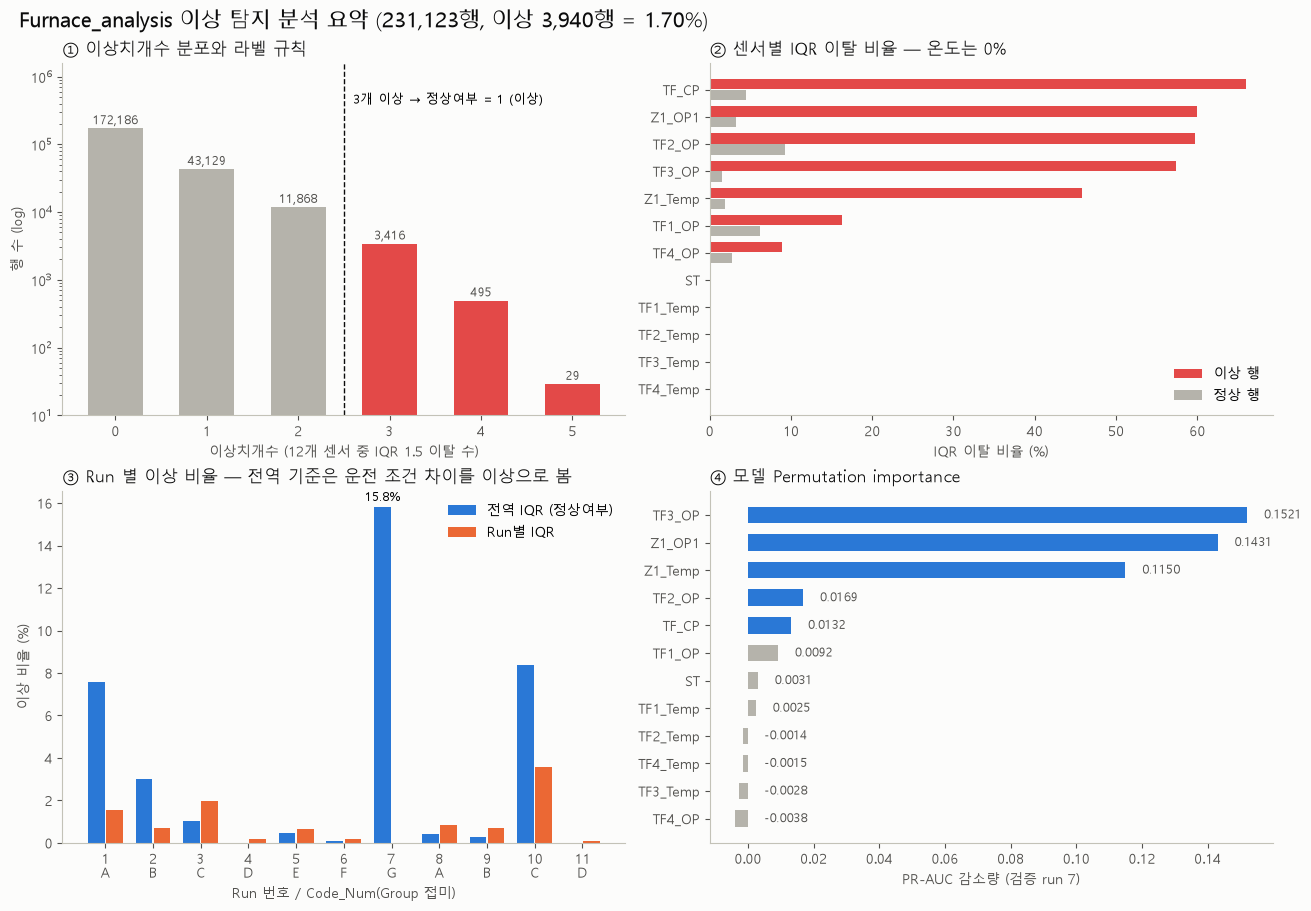

In [14]:
import os
import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams.update({'font.family': 'Malgun Gothic', 'axes.unicode_minus': False, 'font.size': 10,
                     'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': '#52514e', 'xtick.color': '#52514e',
                     'ytick.color': '#52514e', 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
                     'axes.formatter.useoffset': False, 'axes.formatter.limits': (-99, 99)})   # 축 지수 표기 끄기
BLUE, ORANGE, RED, GRAY, INK = '#2a78d6', '#eb6834', '#e34948', '#b5b3ab', '#0b0b0b'
short = lambda s: s.replace('Tube_Furnace', 'TF')

fig, ax = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
fig.suptitle('Furnace_analysis 이상 탐지 분석 요약 (231,123행, 이상 3,940행 = 1.70%)', fontsize=15, color=INK, x=0.01, ha='left')

# ① 이상치개수 분포
a = ax[0, 0]; vc = df['이상치개수'].value_counts().sort_index()
a.bar(vc.index, vc.values, color=[GRAY if k < 3 else RED for k in vc.index], width=0.6)
for k, v in vc.items():
    a.text(k, v * 1.15, f'{v:,}', ha='center', fontsize=9, color='#52514e')
a.set_yscale('log'); a.set_ylim(10, 10 ** 6.2)
a.axvline(2.5, color=INK, lw=1, ls='--'); a.text(2.6, 10 ** 5.6, '3개 이상 → 정상여부 = 1 (이상)', fontsize=9)
a.set_xlabel('이상치개수 (12개 센서 중 IQR 1.5 이탈 수)'); a.set_ylabel('행 수 (log)')
a.set_title('① 이상치개수 분포와 라벨 규칙', loc='left', color=INK)

# ② 센서별 이탈 비율
a = ax[0, 1]; d = drv.sort_values('abnormal_rows_%'); y_ = np.arange(len(d))
a.barh(y_ + 0.2, d['abnormal_rows_%'], height=0.38, color=RED, label='이상 행')
a.barh(y_ - 0.2, d['normal_rows_%'], height=0.38, color=GRAY, label='정상 행')
a.set_yticks(y_, [short(s) for s in d.index]); a.set_xlabel('IQR 이탈 비율 (%)'); a.legend(frameon=False, loc='lower right')
a.set_title('② 센서별 IQR 이탈 비율 — 온도는 0%', loc='left', color=INK)

# ③ Run 별 이상 비율 (전역 vs Run별)
a = ax[1, 0]; x = np.arange(len(cmp)); w = 0.38
a.bar(x - w / 2, cmp['전역 IQR'] * 100, w - 0.03, color=BLUE, label='전역 IQR (정상여부)')
a.bar(x + w / 2, cmp['Run별 IQR'] * 100, w - 0.03, color=ORANGE, label='Run별 IQR')
a.text(x[6] - w / 2, cmp['전역 IQR'].iloc[6] * 100 + 0.3, f"{cmp['전역 IQR'].iloc[6]:.1%}", ha='center', fontsize=9)
a.set_xticks(x, [f'{r}\n{c[-1]}' for r, c in zip(run_tbl.index, run_tbl['Code_Num'])])
a.set_xlabel('Run 번호 / Code_Num(Group 접미)'); a.set_ylabel('이상 비율 (%)'); a.legend(frameon=False)
a.set_title('③ Run 별 이상 비율 — 전역 기준은 운전 조건 차이를 이상으로 봄', loc='left', color=INK)

# ④ 중요도
a = ax[1, 1]; s = imp[::-1]
a.barh([short(i) for i in s.index], s.values, color=[BLUE if v > 0.01 else GRAY for v in s.values], height=0.6)
for i, v in enumerate(s.values):
    a.text(max(v, 0) + 0.005, i, f'{v:,.4f}', va='center', fontsize=8.5, color='#52514e')
a.set_xlabel('PR-AUC 감소량 (검증 run 7)')
a.set_title('④ 모델 Permutation importance', loc='left', color=INK)

os.makedirs('output', exist_ok=True)
fig.savefig('output/Furnace_analysis_summary.png', dpi=150)
plt.show()

## 결론 요약
- **관계**: `Furnace_Tube_Data` 와 행·순서 동일. 차이는 ① 결측 343셀(7개 컬럼)을 **컬럼 전체 평균으로 대체** ② Datetime 에 초(`:00`) 추가 ③ 파생 컬럼 3개
- **파생 규칙 (100% 재현)**
  - `이상치개수` = 12개 수치 컬럼 중 **전역 IQR 1.5배 경계를 벗어난 개수** (결측 대체 후 계산)
  - `정상여부` = `이상치개수 ≥ 3` 이면 1 → **1이 이상**(이름과 반대), 3,940행(1.70%)
  - `요일` = Datetime 요일명 (일요일 없음)
- **이상을 만드는 센서**: CP, Tube_Furnace2/3_OP, Z1_OP1, Z1_Temp. **튜브 온도 4개는 IQR 이탈 0건**
- **이상 집중**: GroupG Run(01-08) 15.80% — 07시 이후 CP 0.45 → 0.11 급락 구간. run 1(7.60%), run 10(8.40%)
- **라벨 한계**: Run별 IQR 로 다시 계산하면 이상 비율 0.73%, GroupG 는 0% → 전역 라벨은 **운전 조건(regime) 차이**를 크게 반영
- **모델**: Run 단위 GroupKFold ROC-AUC 0.987 / PR-AUC 0.745 — 규칙 기반 라벨이라 높은 성능은 당연, Run 이 바뀌면 PR-AUC 가 떨어짐
- 요일·시간대 차이는 Run 과 완전히 겹쳐(confounded) 독립 효과로 해석 불가